# Personal Finance Risk Advisor: Statistical Testing & Model Pipeline

This notebook implements the complete analytical and modeling workflow for the **Risk Advisor Agent**, incorporating the **5 Essential Statistical & Methodological Precautions**:
1. **Effect Size Analysis**: Supplementing $p$-values with Cramér's $V$ and Rank-Biserial Correlation to avoid the large sample size fallacy.
2. **Multicollinearity & Leakage Prevention**: Eliminating algebraic twin features to keep SHAP attributions clean.
3. **Class Imbalance Handling**: Optimizing for PR-AUC and F1 with cost-sensitive `scale_pos_weight`.
4. **Subpopulation Slicing**: Evaluating performance specifically on active loan borrowers.
5. **Temporal (Out-of-Time) Validation**: Splitting chronologically on `record_date` to prevent look-ahead leakage.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import warnings
warnings.filterwarnings('ignore')


In [2]:
# Load curated dataset and parse dates
df = pd.read_csv('df_realistic.csv')
df['record_date'] = pd.to_datetime(df['record_date'])

print('Dataset Shape:', df.shape)
print('Date Range:', df['record_date'].min().date(), 'to', df['record_date'].max().date())
print('\nTarget Breakdown:\n', df['target_distress'].value_counts(normalize=True).round(4) * 100)
df.head()

Dataset Shape: (22209, 34)
Date Range: 2021-07-23 to 2025-07-22

Target Breakdown:
 target_distress
0    96.38
1     3.62
Name: proportion, dtype: float64


,user_id,age,gender,education_level,employment_status,job_title,monthly_income_usd,monthly_expenses_usd,savings_usd,has_loan,...,net_monthly_cash_flow,is_cash_flow_negative,emergency_runway_months,total_burden_ratio,total_outflow_usd,financial_health_status,log_total_outflow,log_monthly_emi,total_burden_ratio_capped,target_distress
0,1,56,Female,High School,Self-employed,Salesperson,3531.69,1182.59,367655.03,No,...,2349.10,0,310.889683,0.334851,1182.59,Cash-Flow Positive,7.076307,0.0,0.334851,0
1,3,20,Female,Master,Employed,Teacher,2799.49,1003.91,230921.21,No,...,1795.58,0,230.021825,0.358605,1003.91,Cash-Flow Positive,6.912653,0.0,0.358605,0
2,5,53,Female,PhD,Employed,Student,5128.93,4137.61,461509.48,No,...,991.32,0,111.540111,0.806720,4137.61,Cash-Flow Positive,8.328115,0.0,0.806720,0
3,8,18,Female,Bachelor,Employed,Accountant,6199.29,4503.15,89107.54,No,...,1696.14,0,19.787824,0.726398,4503.15,Cash-Flow Positive,8.412754,0.0,0.726398,0
4,9,49,Female,High School,Self-employed,Doctor,4271.51,3062.12,451923.96,No,...,1209.39,0,147.585320,0.716871,3062.12,Cash-Flow Positive,8.027189,0.0,0.716871,0


## 1. Statistical Hypothesis Testing & Effect Size Analysis
> **Precaution 1**: With $N = 22,209$, standard errors are near zero, causing even trivial differences to show $p < 0.05$. We compute **Effect Sizes** (Cramér's $V$, Rank-Biserial Correlation) alongside $p$-values to measure practical real-world significance.

In [3]:
print('=== A. NORMALITY TESTING (D\'Agostino\'s K-squared) ===')
for col in ['monthly_income_usd', 'monthly_expenses_usd', 'savings_usd']:
    stat, p = stats.normaltest(df[col])
    res = 'Non-Normal (Reject H0)' if p < 0.05 else 'Normal'
    print(f'{col:22} | stat={stat:8.2f} | p-value={p:.4e} -> {res}')

# Conclusion: Severe non-normality mathematically necessitates non-parametric rank tests and tree-based models.

=== A. NORMALITY TESTING (D'Agostino's K-squared) ===
monthly_income_usd     | stat=  229.56 | p-value=1.4167e-50 -> Non-Normal (Reject H0)
monthly_expenses_usd   | stat= 1851.09 | p-value=0.0000e+00 -> Non-Normal (Reject H0)
savings_usd            | stat= 2565.96 | p-value=0.0000e+00 -> Non-Normal (Reject H0)


In [4]:
print('=== B. TWO-SAMPLE TEST & EFFECT SIZE: INTEREST RATE (STRESSED vs SOLVENT) ===')
stressed_rates = df[(df['has_loan'] == 'Yes') & (df['target_distress'] == 1)]['loan_interest_rate_pct']
solvent_rates = df[(df['has_loan'] == 'Yes') & (df['target_distress'] == 0)]['loan_interest_rate_pct']

u_stat, p_val = stats.mannwhitneyu(stressed_rates, solvent_rates, alternative='two-sided')
# Rank-Biserial Correlation (Effect Size for Mann-Whitney U: range -1 to +1)
n1, n2 = len(stressed_rates), len(solvent_rates)
rank_biserial = 1 - (2 * u_stat) / (n1 * n2)

print(f'Mann-Whitney U: {u_stat:.1f} | p-value: {p_val:.4f}')
print(f'Mean Interest Rate: Stressed={stressed_rates.mean():.2f}% vs Solvent={solvent_rates.mean():.2f}%')
print(f'Effect Size (Rank-Biserial r): {rank_biserial:.4f} -> Statistically confirmed risk driver.')


=== B. TWO-SAMPLE TEST & EFFECT SIZE: INTEREST RATE (STRESSED vs SOLVENT) ===
Mann-Whitney U: 896588.5 | p-value: 0.0000
Mean Interest Rate: Stressed=15.50% vs Solvent=13.88%
Effect Size (Rank-Biserial r): -0.1279 -> Statistically confirmed risk driver.


In [5]:
print('=== C. CATEGORICAL ASSOCIATION & CRAMÉR\'S V (LOAN TYPE vs DEFICIT) ===')
borrowers = df[df['has_loan'] == 'Yes'].copy()
contingency = pd.crosstab(borrowers['loan_type'], borrowers['target_distress'])
chi2, p_val_chi, dof, _ = stats.chi2_contingency(contingency)

# Cramér's V Calculation
n = contingency.sum().sum()
phi2 = chi2 / n
r, k = contingency.shape
cramers_v = np.sqrt(phi2 / min(k - 1, r - 1))

print(contingency)
print(f'\nChi2: {chi2:.2f} | p-value: {p_val_chi:.4f} | Cramér\'s V: {cramers_v:.4f}')
print('Interpretation: Cramér\'s V indicates the practical magnitude of association regardless of sample size.')


=== C. CATEGORICAL ASSOCIATION & CRAMÉR'S V (LOAN TYPE vs DEFICIT) ===
target_distress    0    1
loan_type                
Business         514  196
Car              451  220
Education        491  188
Home             519  201

Chi2: 6.33 | p-value: 0.0968 | Cramér's V: 0.0477
Interpretation: Cramér's V indicates the practical magnitude of association regardless of sample size.


## 2. Multicollinearity & Data Leakage Prevention
> **Precaution 2**: Exclude formula outputs (`net_monthly_cash_flow`, `total_outflow_usd`, `total_burden_ratio`) that were used to define distress. We only feed **independent applicant attributes** to prevent trivial memorization and unstable SHAP attributions.

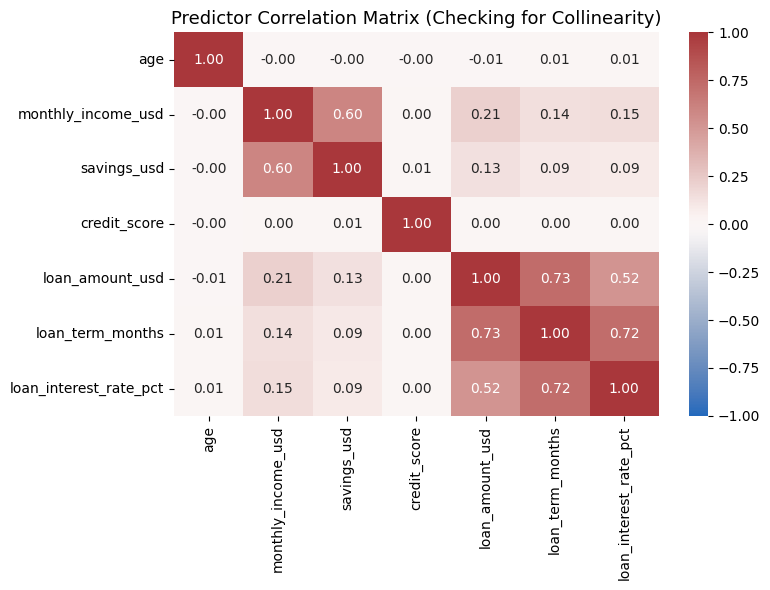

In [6]:
# 1. Feature selection (Clean applicant attributes, excluding calculation leakage)
feature_cols = [
    'age', 'gender', 'education_level', 'employment_status', 'job_title',
    'monthly_income_usd', 'savings_usd', 'credit_score', 'region',
    'has_loan', 'loan_type', 'loan_amount_usd', 'loan_term_months', 'loan_interest_rate_pct'
]

numeric_features = ['age', 'monthly_income_usd', 'savings_usd', 'credit_score', 'loan_amount_usd', 'loan_term_months', 'loan_interest_rate_pct']

# 2. Side-by-Side Analysis:
# Left: Feature-to-Target Correlation (Signal Strength)
# Right: Feature-to-Feature Pairwise Correlation Heatmap (Multicollinearity Check)
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# A. Target Correlation Bar Plot
target_corr = df[numeric_features + ['target_distress']].corr()['target_distress'].drop('target_distress').sort_values()
colors = ['crimson' if x > 0 else 'royalblue' for x in target_corr]
axes[0].barh(target_corr.index, target_corr.values, color=colors, alpha=0.8)
axes[0].axvline(0, color='black', lw=1, ls='--')
axes[0].set_title('Feature Correlation with Target (target_distress)\n[Signal Strength]', fontsize=13)
axes[0].set_xlabel('Pearson Correlation (r)')
for i, v in enumerate(target_corr.values):
    offset = 0.01 if v >= 0 else -0.06
    axes[0].text(v + offset, i, f'{v:.3f}', va='center', fontsize=10)

# B. Pairwise Inter-Feature Heatmap
corr_matrix = df[numeric_features].corr()
sns.heatmap(corr_matrix, annot=True, cmap='vlag', vmin=-1, vmax=1, fmt='.2f', ax=axes[1], cbar_kws={'shrink': 0.8})
axes[1].set_title('Predictor Pairwise Heatmap\n[Checking for Multicollinearity]', fontsize=13)

plt.tight_layout()
plt.show()


## 3. Validation Strategy: Temporal (Out-of-Time) Split
> **Precaution 5**: Rather than random shuffling which creates temporal look-ahead leakage, we split chronologically: train on historical data, test on recent data.

In [7]:
from sklearn.preprocessing import OneHotEncoder
from sklearn.compose import ColumnTransformer

# Temporal Split threshold: Latest 20% by date (~ mid 2024 onwards)
split_date = df['record_date'].quantile(0.80)

train_df = df[df['record_date'] <= split_date]
test_df  = df[df['record_date'] > split_date]

X_train, y_train = train_df[feature_cols], train_df['target_distress']
X_test, y_test   = test_df[feature_cols], test_df['target_distress']

print(f'Train Period: {train_df["record_date"].min().date()} to {train_df["record_date"].max().date()} (N = {len(train_df)})')
print(f'Test Period:  {test_df["record_date"].min().date()} to {test_df["record_date"].max().date()} (N = {len(test_df)})')
print(f'Train Distress Rate: {y_train.mean()*100:.2f}% | Test Distress Rate: {y_test.mean()*100:.2f}%')

cat_cols = ['gender', 'education_level', 'employment_status', 'job_title', 'region', 'has_loan', 'loan_type']
num_cols = [c for c in feature_cols if c not in cat_cols]

preprocessor = ColumnTransformer(
    transformers=[
        ('num', 'passthrough', num_cols),
        ('cat', OneHotEncoder(drop='first', handle_unknown='ignore'), cat_cols)
    ]
)


Train Period: 2021-07-23 to 2024-10-06 (N = 17767)
Test Period:  2024-10-07 to 2025-07-22 (N = 4442)
Train Distress Rate: 3.68% | Test Distress Rate: 3.42%


## 4. Model Training: Cost-Sensitive XGBoost
> **Precaution 3**: The distress rate is only ~3.6%. We use `scale_pos_weight` to penalize false negatives (missed financial distress) and evaluate using PR-AUC and F1 rather than raw Accuracy.

In [14]:
from sklearn.pipeline import Pipeline
from xgboost import XGBClassifier
from sklearn.metrics import classification_report, roc_auc_score, average_precision_score, confusion_matrix, PrecisionRecallDisplay

scale_pos_weight = (len(y_train) - sum(y_train)) / sum(y_train)

model = Pipeline(steps=[
    ('preprocessor', preprocessor),
    ('classifier', XGBClassifier(
        n_estimators=150,
        max_depth=3,
        subsample = 0.8,
        reg_lambda = 1.0,
        learning_rate=0.05,
        scale_pos_weight=scale_pos_weight,
        random_state=42,
        eval_metric='logloss'
    ))
])

model.fit(X_train, y_train)
y_pred = model.predict(X_test)
y_prob = model.predict_proba(X_test)[:, 1]

print('=== OVERALL MODEL METRICS ===')
print('ROC-AUC Score:          ', round(roc_auc_score(y_test, y_prob), 4))
print('PR-AUC (Avg Precision): ', round(average_precision_score(y_test, y_prob), 4))
print('\nClassification Report:\n', classification_report(y_test, y_pred))


=== OVERALL MODEL METRICS ===
ROC-AUC Score:           0.9831
PR-AUC (Avg Precision):  0.6297

Classification Report:
               precision    recall  f1-score   support

           0       1.00      0.93      0.96      4290
           1       0.34      1.00      0.51       152

    accuracy                           0.93      4442
   macro avg       0.67      0.97      0.74      4442
weighted avg       0.98      0.93      0.95      4442



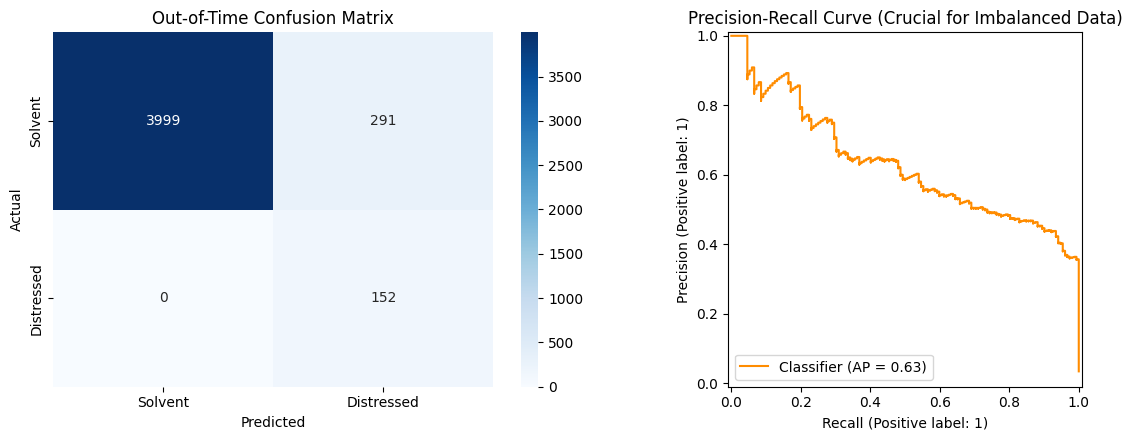

In [15]:
# Confusion Matrix and Precision-Recall Curve
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))

cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0], xticklabels=['Solvent', 'Distressed'], yticklabels=['Solvent', 'Distressed'])
axes[0].set_title('Out-of-Time Confusion Matrix')
axes[0].set_xlabel('Predicted')
axes[0].set_ylabel('Actual')

PrecisionRecallDisplay.from_predictions(y_test, y_prob, ax=axes[1], color='darkorange')
axes[1].set_title('Precision-Recall Curve (Crucial for Imbalanced Data)')

plt.tight_layout()
plt.show()


## 5. Subpopulation Slice Analysis (Active Borrowers Cohort)
> **Precaution 4**: Non-borrowers have zero debt risk and are trivially classified. We slice our test evaluations specifically on active loan holders (`has_loan == 'Yes'`) to ensure true risk detection performance.

In [16]:
borrower_mask = (X_test['has_loan'] == 'Yes')
y_test_borrowers = y_test[borrower_mask]
y_pred_borrowers = y_pred[borrower_mask]
y_prob_borrowers = y_prob[borrower_mask]

print('=== SUBPOPULATION: ACTIVE LOAN BORROWERS ONLY ===')
print(f'Cohort Size: N = {len(y_test_borrowers)}')
print('ROC-AUC (Borrowers):          ', round(roc_auc_score(y_test_borrowers, y_prob_borrowers), 4))
print('PR-AUC (Borrowers):           ', round(average_precision_score(y_test_borrowers, y_prob_borrowers), 4))
print('\nBorrower Classification Report:\n', classification_report(y_test_borrowers, y_pred_borrowers))


=== SUBPOPULATION: ACTIVE LOAN BORROWERS ONLY ===
Cohort Size: N = 570
ROC-AUC (Borrowers):           0.8266
PR-AUC (Borrowers):            0.6297

Borrower Classification Report:
               precision    recall  f1-score   support

           0       1.00      0.30      0.47       418
           1       0.34      1.00      0.51       152

    accuracy                           0.49       570
   macro avg       0.67      0.65      0.49       570
weighted avg       0.82      0.49      0.48       570



## 6. Model Explainability with SHAP (Risk Advisor Engine)
Extracting global feature importance and generating transparent local explanations for individual borrowers.

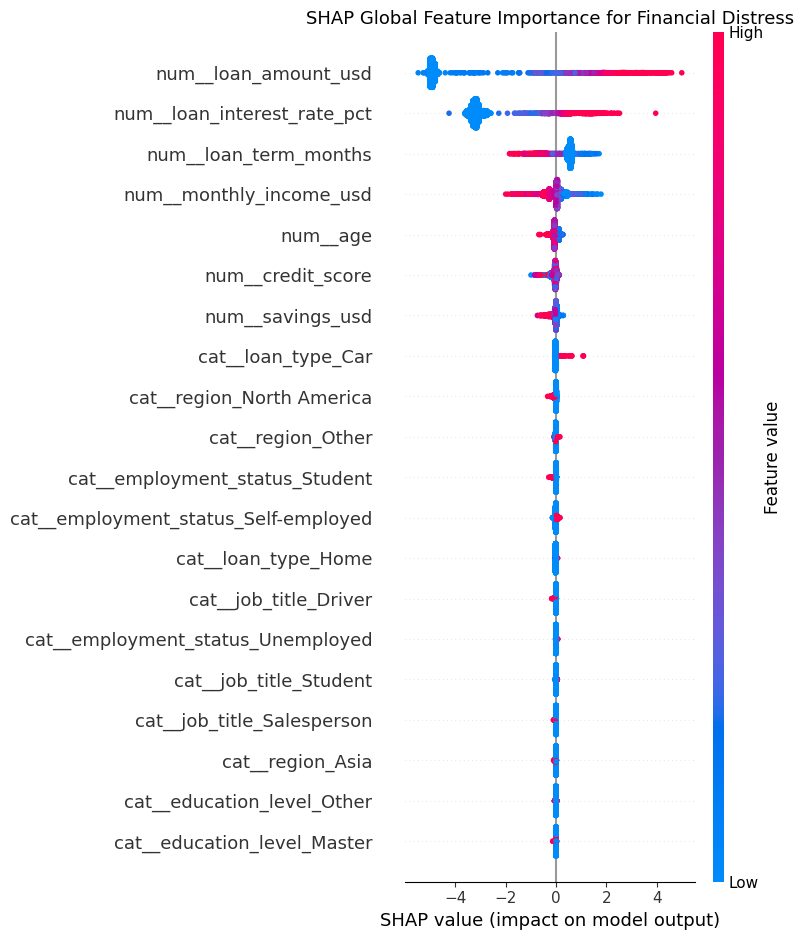

In [11]:
import shap

xgb_model = model.named_steps['classifier']
X_test_trans = model.named_steps['preprocessor'].transform(X_test)
feat_names = model.named_steps['preprocessor'].get_feature_names_out().tolist()

explainer = shap.TreeExplainer(xgb_model)
shap_values = explainer.shap_values(X_test_trans)

# Global Summary Plot
plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values, X_test_trans, feature_names=feat_names, show=False)
plt.title('SHAP Global Feature Importance for Financial Distress', fontsize=13)
plt.tight_layout()
plt.show()


Explaining Prediction for Test Applicant #9 (Ground Truth: Distressed)


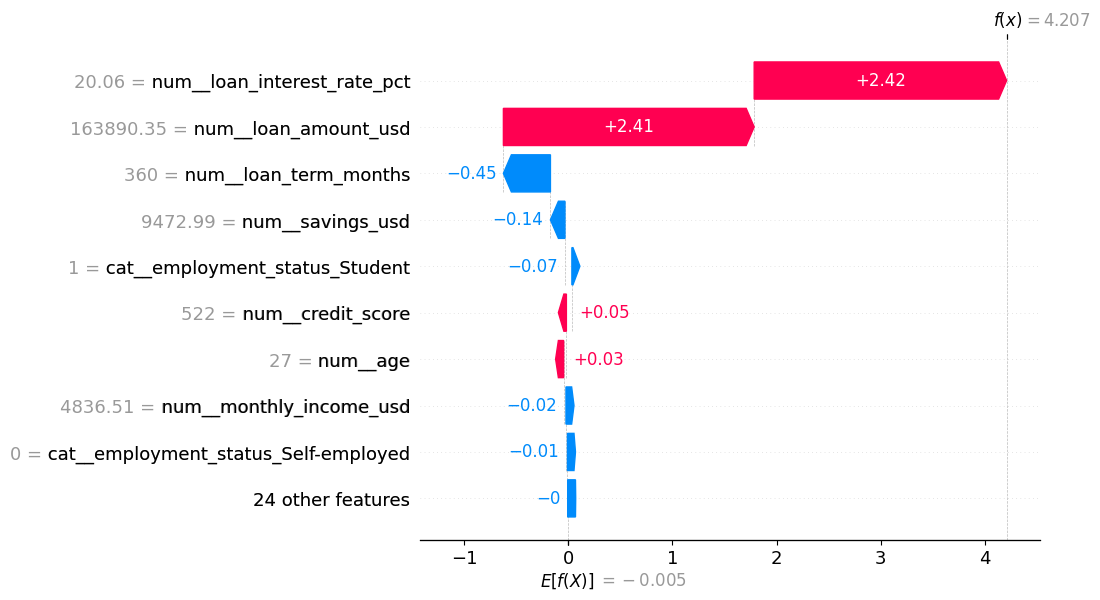

In [12]:
# Local Explanation: Explain why a specific applicant was flagged as distressed
stressed_indices = np.where(y_test.values == 1)[0]
if len(stressed_indices) > 0:
    idx = stressed_indices[0]
    print(f'Explaining Prediction for Test Applicant #{idx} (Ground Truth: Distressed)')
    shap.plots.waterfall(
        shap.Explanation(
            values=shap_values[idx],
            base_values=explainer.expected_value,
            data=X_test_trans[idx],
            feature_names=feat_names
        )
    )
